# Water detection with Sentinel-1 <img align="right" src="../Supplementary_data/DE_Africa_Logo_Stacked_RGB_small.jpg">

* **Products used:** 
[s1_rtc](https://explorer.digitalearth.africa/products/s1_rtc)

## Background

Over 40% of the world’s population lives within 100 km of the coastline.
However, coastal environments are constantly changing, with erosion and coastal change presenting a major challenge to valuable coastal infrastructure and important ecological habitats.
Updating data on the position of the coastline is essential for coastal managers to be able to identify and minimise the impacts of coastal change and erosion. 
The coastal regions are also home to many wetlands. Monitoring of water extent helps to understand and protect these dynamic and productive ecosystems.

While coastlines and water extents can be mapped using optical data (demonstrated in the [Coastal Erosion notebook](../Real_world_examples/Coastal_erosion.ipynb)), these images can be strongly affected by the weather, especially through the presence of clouds, which obscure the land and water below.
This can be a particular problem in cloudy regions or areas where clouds in wet season prevent optical satellites from taking clear images for many months of the year.

Radar observations are largely unaffected by cloud cover.
The two Sentinel-1 satellites, operated by ESA as part of the Copernicus program, provide all-weather observations every 6 to 12 days over Africa.
By developing a process to classify the observed pixels as either water or land, it is possible to identify the shoreline and map the dynamic water extents using radar data.
For more information, see the [Sentinel-1](../Datasets/Sentinel_1.ipynb) notebook.

## Description

In this example, we use data from the Sentinel-1 satellites to build a classifier that can determine whether a pixel is a water or land.
Specifically, this notebook uses analysis-ready radar backscatter, which describes the strength of the signal received by the satellite.

The notebook contains the following steps:

1. Load Sentinel-1 backscatter data for an area of interest and visualize the returned data
2. Applying speckle filter and converting the digital numbers to dB values for analysis
3. Use histogram analysis to determine the threshold for water classification
4. Design a classifier to distinguish land and water
5. Apply the classifier to the area of interest and interpret the results

***

## Getting started

To run this analysis, run all the cells in the notebook, starting with the "Load packages" cell. 

### Load packages
Import Python packages that are used for the analysis.

In [1]:
%matplotlib inline

import os 
import warnings 
import datacube
import numpy as np
import xarray as xr
import geopandas as gpd
import matplotlib.pyplot as plt
warnings.filterwarnings("ignore")

from scipy.ndimage.filters import uniform_filter
from scipy.ndimage.measurements import variance
from skimage.filters import threshold_minimum
from odc.geo.geom import Geometry
from deafrica_tools.spatial import xr_rasterize
from deafrica_tools.datahandling import load_ard
from deafrica_tools.plotting import display_map, rgb
from deafrica_tools.areaofinterest import define_area

### Connect to the datacube

Connect to the datacube so we can access DEA data.
The `app` parameter is a unique name for the analysis which is based on the notebook file name.

In [2]:
dc = datacube.Datacube(app="Radar_water_detection")

### Analysis parameters

The following cell sets the parameters, which define the area of interest and the length of time to conduct the analysis.
The parameters are

* `lat`: The central latitude to analyse (e.g. `10.338`).
* `lon`: The central longitude to analyse (e.g. `-1.055`).
* `buffer`: The number of square degrees to load around the central latitude and longitude. 
For reasonable loading times, set this as `0.1` or lower.
* `time_range`: The date range to analyse (e.g. `('2020') `)

**If running the notebook for the first time**, keep the default settings below.
This will demonstrate how the analysis works and provide meaningful results.
The example covers the coast of Ziguinchor, Gambia.


### Select location
To define the area of interest, there are two methods available:

1. By specifying the latitude, longitude, and buffer. This method requires you to input the central latitude, central longitude, and the buffer value in square degrees around the center point you want to analyze. For example, `lat = 10.338`, `lon = -1.055`, and `buffer = 0.1` will select an area with a radius of 0.1 square degrees around the point with coordinates (10.338, -1.055).

    Alternatively, you can provide separate buffer values for latitude and longitude for a rectangular area. For example, `lat = 10.338`, `lon = -1.055`, and `lat_buffer = 0.1` and`lon_buffer = 0.08` will select a rectangular area extending 0.1 degrees north and south, and 0.08 degrees east and west from the point `(10.338, -1.055)`.

   For reasonable loading times, set the buffer as `0.1` or lower.

2. By uploading a polygon as a `GeoJSON or Esri Shapefile`. If you choose this option, you will need to upload the geojson or ESRI shapefile into the Sandbox using Upload Files button <img align="top" src="../Supplementary_data/upload_files_icon.png"> in the top left corner of the Jupyter Notebook interface. ESRI shapefiles must be uploaded with all the related files `(.cpg, .dbf, .shp, .shx)`. Once uploaded, you can use the shapefile or geojson to define the area of interest. Remember to update the code to call the file you have uploaded.

To use one of these methods, you can uncomment the relevant line of code and comment out the other one. To comment out a line, add the `"#"` symbol before the code you want to comment out. By default, the first option which defines the location using latitude, longitude, and buffer is being used.

The selected latitude and longitude will be displayed as a red box on the map below the next cell. 
This map can be used to find coordinates of other places, simply scroll and click on any point on the map to display the latitude and longitude of that location.

In [3]:
# Method 1: Specify the latitude, longitude, and buffer
aoi = define_area(lat=10.338, lon=-1.055, buffer=0.05)

# Method 2: Use a polygon as a GeoJSON or Esri Shapefile. 
#aoi = define_area(vector_path='aoi.shp')

#Create a geopolygon and geodataframe of the area of interest
geopolygon = Geometry(aoi["features"][0]["geometry"], crs="epsg:4326")
geopolygon_gdf = gpd.GeoDataFrame(geometry=[geopolygon], crs=geopolygon.crs)

# Get the latitude and longitude range of the geopolygon
lat_range = (geopolygon_gdf.total_bounds[1], geopolygon_gdf.total_bounds[3])
lon_range = (geopolygon_gdf.total_bounds[0], geopolygon_gdf.total_bounds[2])

#timeframe
timerange = ('2023-01-01', '2023-12-31')

## View the selected location
The next cell will display the selected area on an interactive map.
Feel free to zoom in and out to get a better understanding of the area you'll be analysing.
Clicking on any point of the map will reveal the latitude and longitude coordinates of that point.

In [30]:
display_map(x=lon_range, y=lat_range)

## Load and view Sentinel-1 data

The first step in the analysis is to load Sentinel-1 backscatter data for the specified area of interest. This uses the pre-defined [load_ard](../Frequently_used_code/Using_load_ard.ipynb) utility function. 

**Please be patient**.
The data may take a few minutes to load and progress will be indicated by text output.
The load is complete when the cell status goes from `[*]` to `[number]`.

In [5]:
# Load the Sentinel-1 data
S1 = load_ard(dc=dc,
              products=["s1_rtc"],
              measurements=['vv', 'vh'],
              y=lat_range,
              x=lon_range,
              time=timerange,
              output_crs = "EPSG:6933",
              resolution = (-20,20),
              group_by="solar_day",
              dtype='native'
             )

Using pixel quality parameters for Sentinel 1
Finding datasets
    s1_rtc
Applying pixel quality/cloud mask
Loading 30 time steps


**Once the load is complete**, examine the data by printing it in the next cell.
The `Dimensions` argument reveals the number of time steps in the data set, as well as the number of pixels in the `x` (longitude) and `y` (latitude) dimensions.

In [6]:
print(S1)

<xarray.Dataset> Size: 73MB
Dimensions:      (time: 30, y: 629, x: 483)
Coordinates:
  * time         (time) datetime64[ns] 240B 2023-01-01T18:19:52.184489 ... 20...
  * y            (y) float64 5kB 1.318e+06 1.318e+06 ... 1.306e+06 1.306e+06
  * x            (x) float64 4kB -1.066e+05 -1.066e+05 ... -9.699e+04 -9.697e+04
    spatial_ref  int32 4B 6933
Data variables:
    vv           (time, y, x) float32 36MB 0.04423 0.05769 ... 0.0447 0.04514
    vh           (time, y, x) float32 36MB 0.006281 0.004911 ... 0.00875
Attributes:
    crs:           EPSG:6933
    grid_mapping:  spatial_ref


### Visualize the time series

Coastal and wetlands are highly dynamic, so cloud-free assessment using radar is valuable to capture change in all seasons. In the next few cells, Sentinel-1 observations in different polarisations are plotted for selected dates. Noting VV backscatter is usually significantly higher than VH. Signals from the two polarizations are dominated by different scattering mechanisms therefore respond differently to surface characeristics. 

Both polarizations show siginficant surface cover change over time. Open water is characterized by low backscatter due to specular reflection. Water area with standing vegetation leads to high backscatter and will not be mapped using the thresholding method below. This may result in differenct water extent measurement compared to methods using optical data.

In [7]:
#Selecting a few images from the loaded S1 to visualise 
timesteps = [2,4,6,9,11]

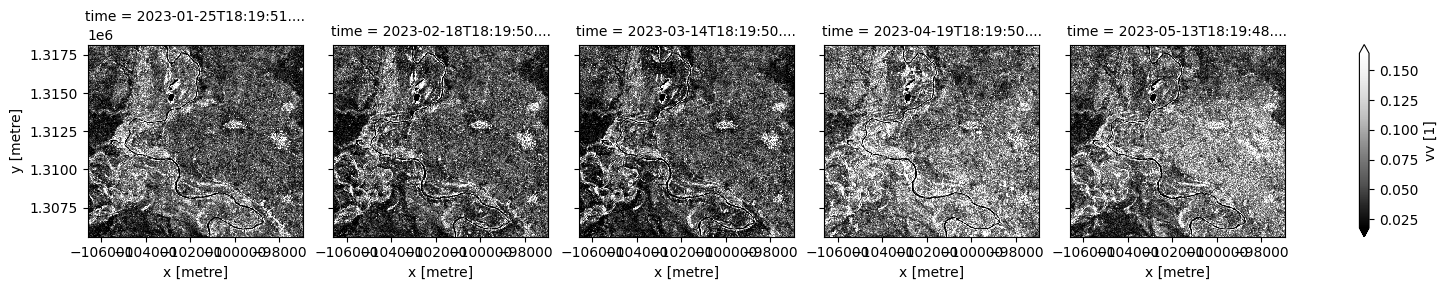

In [8]:
# Plot VV polarisation for specific timeframe 
S1.vv.isel(time=timesteps).plot(cmap="Greys_r", robust=True, col="time", col_wrap=5);

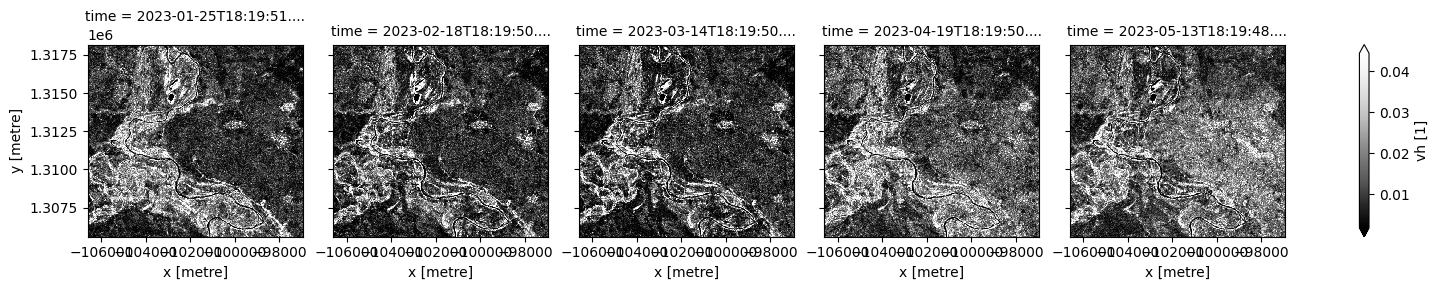

In [9]:
# Plot VH polarisation for specific timeframe 
S1.vh.isel(time=timesteps).plot(cmap="Greys_r", robust=True, col="time", col_wrap=5);

Backscatter measurements can be combined in visualization to highlight the different polarization signatures. 
For the RGB visualization below, the ratio between VH and VV is added as a third measurement band.

In [10]:
# VH/VV is a potentially useful third feature after VV and VH 
S1['vh/vv'] = S1.vh/S1.vv

In [11]:
# median values are used to scale the measurements so they have a similar range for visualization
med_s1 = S1[['vv','vh','vh/vv']].median()

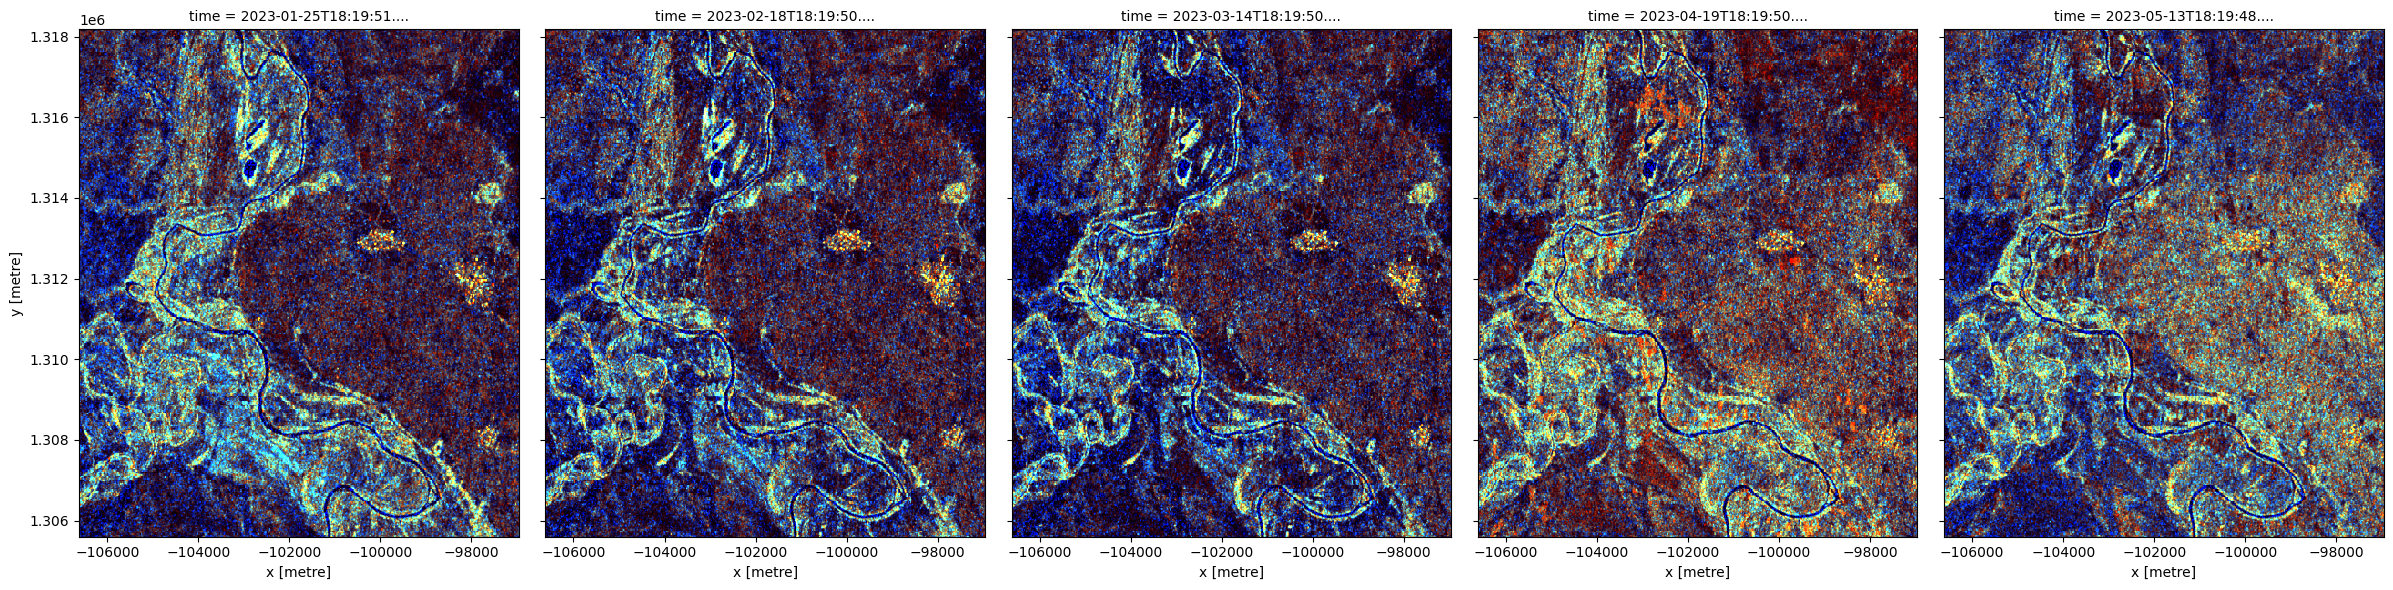

In [12]:
# plotting an RGB image for selected timesteps
rgb(S1[['vv', 'vh', 'vh/vv']]/med_s1, bands=['vv',
    'vh', 'vh/vv'], index=timesteps, col_wrap=5);

Significant changes in color pattern are visible from month to month. 
Open water and smooth bare surface appear dark blue because all measurements are low. 
Tree cover appears cyan because of the relatively higher VH signal from volume scattering. 
Areas in bright red are likely water with standing vegetation.
Urban area is shown in bright yellow at the bottom of the images.

## Apply speckle filtering

Radar observations appear speckly due to random interference of coherent signals from target scatters. 
The speckle noise can be reduced by averaging pixel values over an area or over time. 
However, averaging over a fixed window smoothes out real local spatial variation and leads to reduced spatial resolution.
An adaptive approach that takes into account local homogeneity is therefore preferred.

Below, we apply the Lee filter, one of the popular adaptive speckle filters.


In [13]:
#defining a function to apply lee filtering on S1 image 
def lee_filter(da, size):
    """
    Apply lee filter of specified window size.
    Adapted from https://stackoverflow.com/questions/39785970/speckle-lee-filter-in-python

    """
    img = da.values
    img_mean = uniform_filter(img, size)
    img_sqr_mean = uniform_filter(img**2, size)
    img_variance = img_sqr_mean - img_mean**2

    overall_variance = variance(img)

    img_weights = img_variance / (img_variance + overall_variance)
    img_output = img_mean + img_weights * (img - img_mean)
    
    return img_output

Now that we've defined the filter, we can run it on the VV and VH data. You might have noticed that the function takes a size argument. This will change how blurred the image becomes after smoothing. We've picked a default value for this analysis, but you can experiement with this if you're interested.

In [14]:
# The lee filter above doesn't handle null values
# We therefore set null values to 0 before applying the filter
valid = np.isfinite(S1)
S1 = S1.where(valid, 0)

# Create a new entry in dataset corresponding to filtered VV and VH data
S1["filtered_vv"] = S1.vv.groupby("time").apply(lee_filter, size=7)
S1["filtered_vh"] = S1.vh.groupby("time").apply(lee_filter, size=7)

# Null pixels should remain null
S1['filtered_vv'] = S1.filtered_vv.where(valid.vv)
S1['filtered_vh'] = S1.filtered_vh.where(valid.vh)

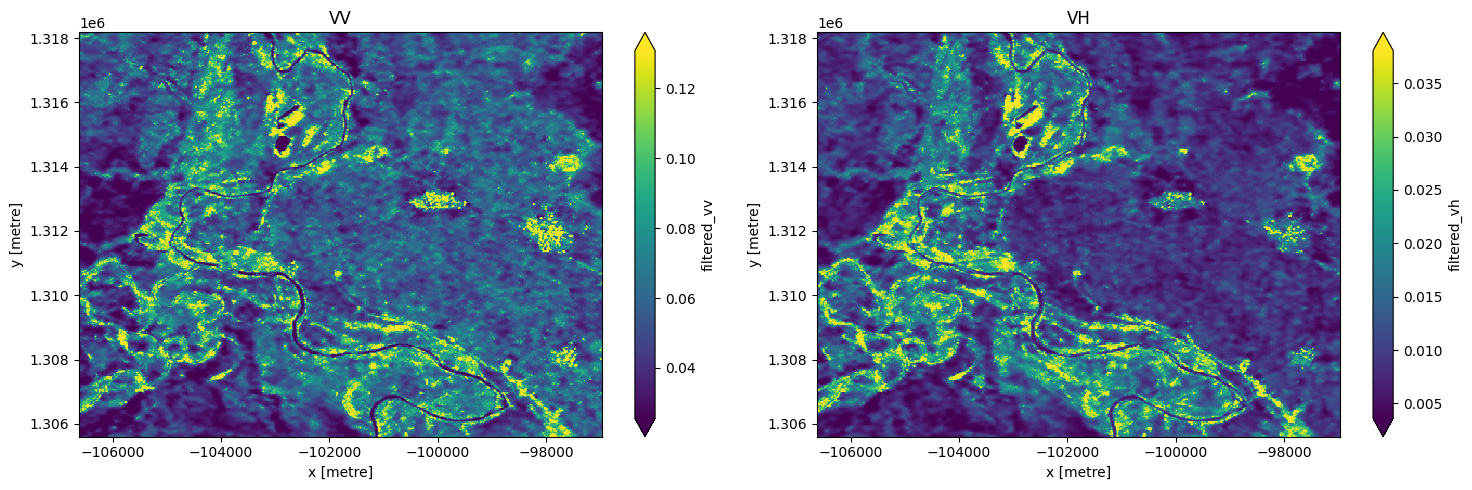

In [15]:
# images appear smoother after speckle filtering
fig, ax = plt.subplots(1, 2, figsize=(15,5))
S1["filtered_vv"].isel(time=3).plot(ax = ax[0],robust=True)
S1["filtered_vh"].isel(time=3).plot(ax = ax[1],robust=True);
ax[0].set_title('VV')
ax[1].set_title('VH')
plt.tight_layout();

### Convert the digital numbers to dB

While Sentinel-1 backscatter is provided as linear intensity, it is often useful to convert the backscatter to decible (dB) for analysis. 
Backscatter in dB unit has a more symmetric noise profile and less skewed value distribution for easier statistical evaluation.

In [16]:
S1['filtered_vv'] = 10 * np.log10(S1.filtered_vv)
S1['filtered_vh'] = 10 * np.log10(S1.filtered_vh)

## Histogram analysis for Sentinel-1

Backscatter distributions are plotted below as histograms.

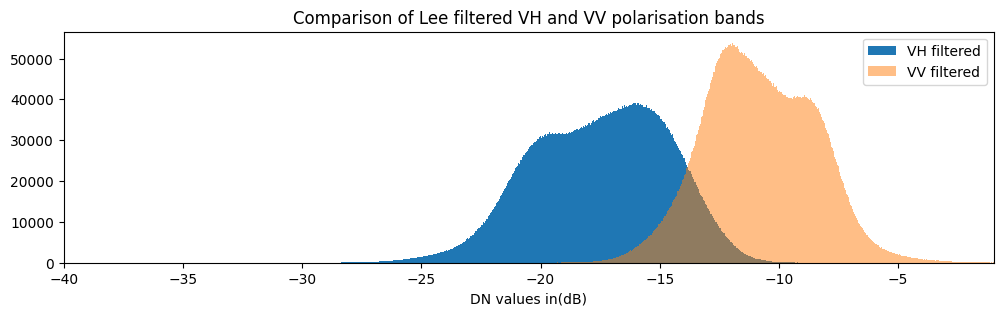

In [17]:
fig = plt.figure(figsize=(12, 3))
S1.filtered_vh.plot.hist(bins=1000, label="VH filtered")
S1.filtered_vv.plot.hist(bins=1000, label="VV filtered",alpha=0.5)
plt.xlim(-40,-1)
plt.legend()
plt.xlabel("DN values in(dB)")
plt.title("Comparison of Lee filtered VH and VV polarisation bands");

## Build and apply the classifier 

The histogram for VH backscatter shows a bimodal distribution with low values over water and high values over land.
The VV histogram has multiple peaks and less obvious seperation between water and land.

We therefore build a classifier based on VH backscatter. We choose a threshold to separate land and water: pixels with values below the threshold are water, and pixels with values above the threshold are not water (land).

There are several ways to determine the threshold. 
Here, we use the `threshod_minimum` function implemented in the `skimage` package to determine the threshold from the *VH* histogram automatically.
This method computes the histogram for all backscatter values, smooths it until there are only two maxima and find the minimum in between as the threshold.

In [31]:
threshold_vh = -24 #threshold_minimum(S1.filtered_vh.values)

print(threshold_vh)

-24


### Visualise threshold

To check if our chosen threshold reasonably divides the two distributions, we can add the threshold to the histogram plots we made earlier. 

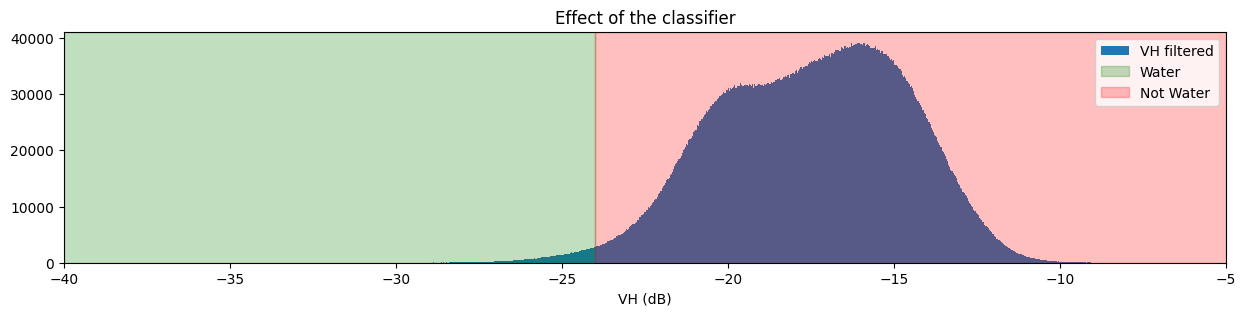

In [32]:
fig, ax = plt.subplots(figsize=(15, 3))
S1.filtered_vh.plot.hist(bins=1000, label="VH filtered")
plt.xlim(-40,-5)
ax.axvspan(xmin=-40.0, xmax=threshold_vh, alpha=0.25, color="green", label="Water")
ax.axvspan(xmin=threshold_vh,
           xmax=-5,
           alpha=0.25,
           color="red",
           label="Not Water")
plt.legend()
plt.xlabel("VH (dB)")
plt.title("Effect of the classifier")
plt.show()

### Define the classifier

This threshold is used to write a function to only return the pixels that are classified as water. The basic steps that the function will perform are:

1. Find all pixels that have filtered values lower than the threshold; these are the `water` pixels.
2. Return a data set containing the `water` pixels.


In [33]:
def S1_water_classifier(da, threshold=threshold_vh):
    water_data_array = da < threshold
    return water_data_array.to_dataset(name="s1_water")

Now that we have defined the classifier function, we can apply it to the data. After running the classifier, we will able to view the classified data product by running `print(S1.water)`.

In [34]:
S1['water'] = S1_water_classifier(S1.filtered_vh).s1_water

Pre-flood date: 2023-01-01
Flood peak date: 2023-09-10


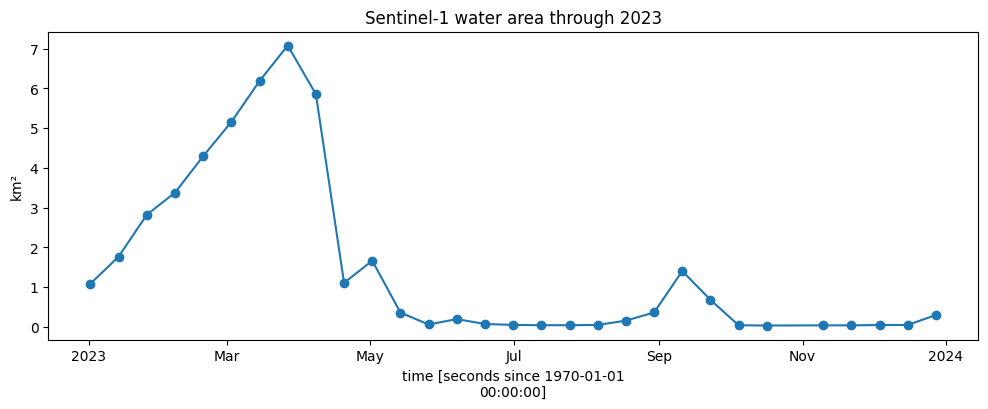

In [35]:
area_per_pixel = (20 * 20) / 1e6   # km² per 20 m pixel

# Water area (km²) in every radar image
water_area = S1.water.sum(dim=['x', 'y']) * area_per_pixel
water_area.plot(marker='o', figsize=(12, 4))
plt.title('Sentinel-1 water area through 2023'); plt.ylabel('km²')

# Pre-flood = driest image in Jan-Mar, flood peak = wettest image in Aug-Oct
months = water_area.time.dt.month
pre_date   = water_area.where(months.isin([1, 2, 3]), drop=True).idxmin('time')
flood_date = water_area.where(months.isin([8, 9, 10]), drop=True).idxmax('time')
print('Pre-flood date:', str(pre_date.values)[:10])
print('Flood peak date:', str(flood_date.values)[:10])

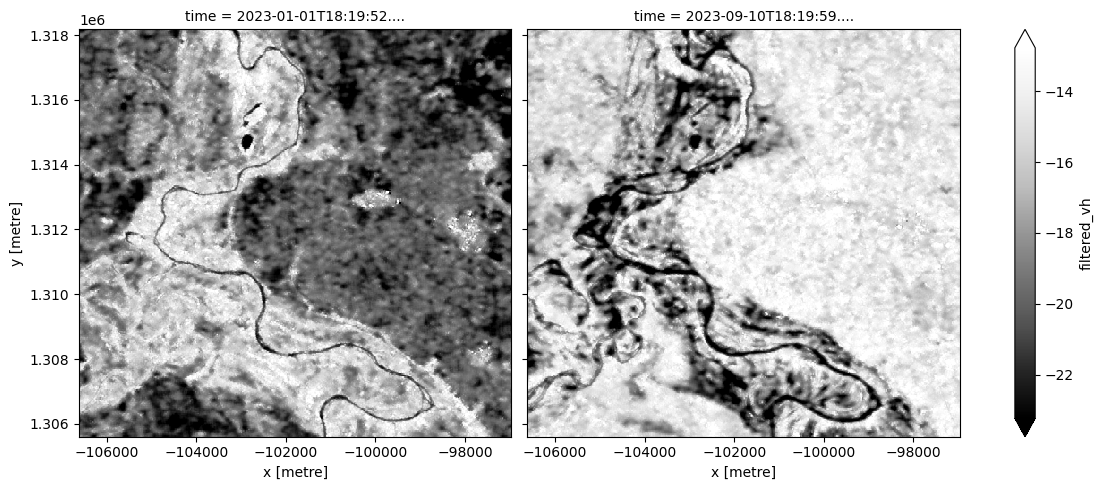

In [36]:
S1.filtered_vh.sel(time=[pre_date.values, flood_date.values]).plot(
    col='time', cmap='Greys_r', robust=True, figsize=(12, 5));

Permanent water (km²): 0.04
Newly flooded land (km²): 1.36
Study area (km²): 121.5
Share of study area flooded (%): 1.1


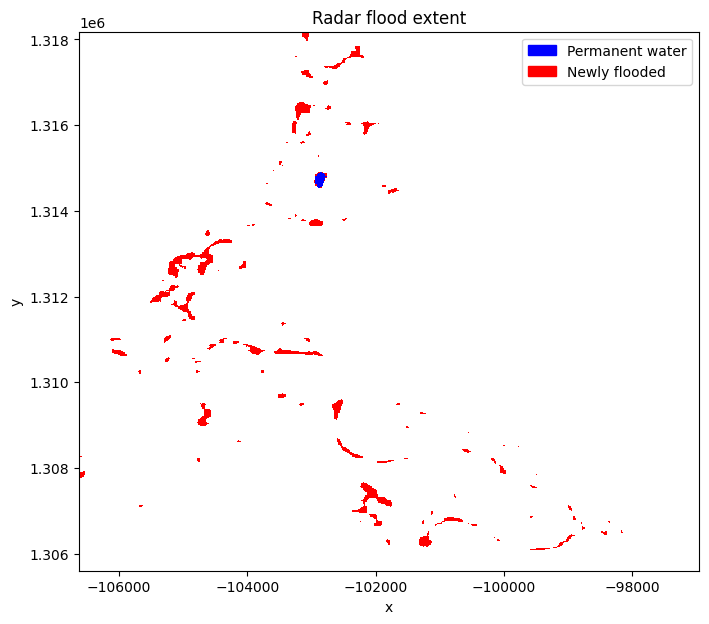

In [37]:
import matplotlib.colors as mcolors
from matplotlib.patches import Patch

pre   = S1.water.sel(time=pre_date.values)
flood = S1.water.sel(time=flood_date.values)

flooded   = flood & ~pre      # water at flood peak, land before
permanent = flood & pre       # water in both

cls = xr.where(flooded, 2, xr.where(permanent, 1, 0))

plt.figure(figsize=(8, 7))
cls.plot(cmap=mcolors.ListedColormap(['white', 'blue', 'red']),
         vmin=-0.5, vmax=2.5, add_colorbar=False)
plt.legend(handles=[Patch(color='blue', label='Permanent water'),
                    Patch(color='red', label='Newly flooded')])
plt.title('Radar flood extent')

total_area = S1.water.isel(time=0).size * area_per_pixel
flood_km2 = float(flooded.sum()) * area_per_pixel
print('Permanent water (km²):', round(float(permanent.sum()) * area_per_pixel, 2))
print('Newly flooded land (km²):', round(flood_km2, 2))
print('Study area (km²):', round(total_area, 1))
print('Share of study area flooded (%):', round(flood_km2 / total_area * 100, 1))

---

## Additional information

<b> License </b> The code in this notebook is licensed under the [Apache License, Version 2.0](https://www.apache.org/licenses/LICENSE-2.0).

Digital Earth Africa data is licensed under the [Creative Commons by Attribution 4.0](https://creativecommons.org/licenses/by/4.0/) license.

<b> Contact </b> If you need assistance, please post a question on the [DE Africa Slack channel](https://digitalearthafrica.slack.com/) or on the [GIS Stack Exchange](https://gis.stackexchange.com/questions/ask?tags=open-data-cube) using the `open-data-cube` tag (you can view previously asked questions [here](https://gis.stackexchange.com/questions/tagged/open-data-cube)).

If you would like to report an issue with this notebook, you can file one on [Github](https://github.com/digitalearthafrica/deafrica-sandbox-notebooks).

<b> Compatible datacube version </b>

In [22]:
print(datacube.__version__)

1.9.13


**Last Tested:**

In [23]:
from datetime import datetime
datetime.today().strftime('%Y-%m-%d')

'2026-10-15'